In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()


Saving train.csv to train.csv


In [2]:

df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:

print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in important columns:")
print(
    df[
        ["GrLivArea", "BedroomAbvGr", "OverallQual", "SalePrice"]
    ].isnull().sum()
)

print("\nStatistical summary:")
print(df[["GrLivArea", "BedroomAbvGr", "OverallQual", "SalePrice"]].describe())


Rows and columns: (1460, 81)

Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3Ss

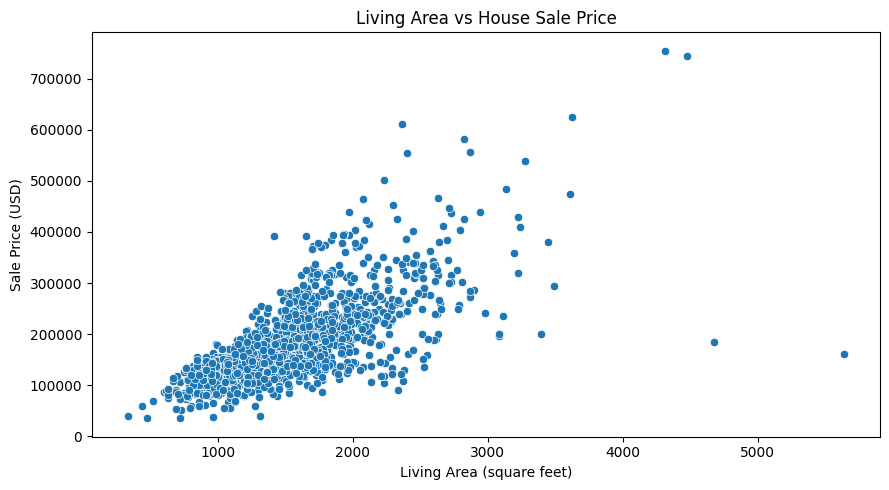

In [6]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs House Sale Price")
plt.xlabel("Living Area (square feet)")
plt.ylabel("Sale Price (USD)")

plt.tight_layout()
plt.show()


In [7]:
# Check how the features are related to SalePrice

correlation = df[
    ["GrLivArea", "BedroomAbvGr", "OverallQual", "SalePrice"]
].corr()

print(correlation["SalePrice"].sort_values(ascending=False))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
BedroomAbvGr    0.168213
Name: SalePrice, dtype: float64


In [8]:
# Input features (X)
X = df[["GrLivArea", "OverallQual", "BedroomAbvGr"]]

# Target variable (y)
y = df["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 5 input rows:")
display(X.head())

print("\nFirst 5 actual prices:")
display(y.head())

Features shape: (1460, 3)
Target shape: (1460,)

First 5 input rows:


,GrLivArea,OverallQual,BedroomAbvGr
0,1710,7,3
1,1262,6,3
2,1786,7,3
3,1717,7,3
4,2198,8,4



First 5 actual prices:


,SalePrice
0,208500
1,181500
2,223500
3,140000
4,250000


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training input rows:", X_train.shape[0])
print("Testing input rows:", X_test.shape[0])
print("Training target rows:", y_train.shape[0])
print("Testing target rows:", y_test.shape[0])

Training input rows: 1168
Testing input rows: 292
Training target rows: 1168
Testing target rows: 292


In [10]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [11]:
# Predict prices for unseen test houses
y_pred = model.predict(X_test)

print("First 10 predicted prices:")
print(y_pred[:10])

print("\nFirst 10 actual prices:")
print(y_test.iloc[:10].to_numpy())

First 10 predicted prices:
[146860.52690738 308271.96965801 124521.48414718 185394.49851843
 284674.11365282  79036.19669445 234613.56859411 171946.40104343
  79036.19669445 137403.86042363]

First 10 actual prices:
[154500 325000 115000 159000 315500  75500 311500 146000  84500 135500]


In [12]:
comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred
})

comparison["Difference"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

display(comparison.head(10).round(2))

,Actual Price,Predicted Price,Difference
0,154500,146860.53,7639.47
1,325000,308271.97,16728.03
2,115000,124521.48,-9521.48
3,159000,185394.50,-26394.50
4,315500,284674.11,30825.89
5,75500,79036.20,-3536.20
6,311500,234613.57,76886.43
7,146000,171946.40,-25946.40
8,84500,79036.20,5463.80
9,135500,137403.86,-1903.86


In [13]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))

Mean Absolute Error (MAE): 28159.91


In [14]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R-squared score:", round(r2, 4))

R-squared score: 0.7612


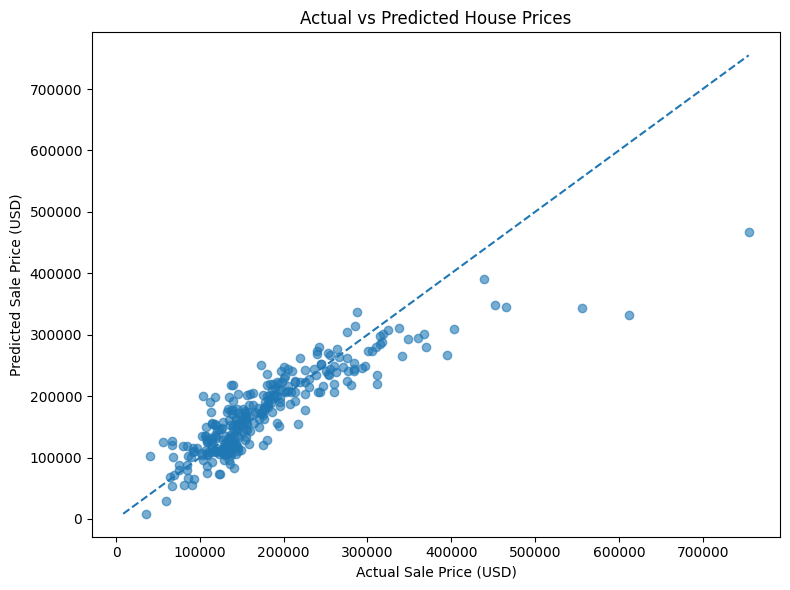

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Reference line: perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Sale Price (USD)")
plt.ylabel("Predicted Sale Price (USD)")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Select additional numerical features
features = [
    "GrLivArea",
    "OverallQual",
    "BedroomAbvGr",
    "GarageCars",
    "TotalBsmtSF",
    "YearBuilt"
]

X = df[features].copy()
y = df["SalePrice"]

# Handle missing values in selected features
X = X.fillna(X.median())

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the improved model
model_improved = LinearRegression()
model_improved.fit(X_train, y_train)

# Make predictions
y_pred_improved = model_improved.predict(X_test)

# Evaluate
mae_improved = mean_absolute_error(y_test, y_pred_improved)
r2_improved = r2_score(y_test, y_pred_improved)

print("Improved Model MAE:", round(mae_improved, 2))
print("Improved Model R²:", round(r2_improved, 4))

Improved Model MAE: 25166.4
Improved Model R²: 0.8018


In [17]:
# Sample house details
new_house = pd.DataFrame([{
    "GrLivArea": 2000,
    "OverallQual": 7,
    "BedroomAbvGr": 3,
    "GarageCars": 2,
    "TotalBsmtSF": 1000,
    "YearBuilt": 2005
}])

# Predict the house price
predicted_price = model_improved.predict(new_house)[0]

print("Sample House Details:")
display(new_house)

print("Predicted Sale Price: ${:,.2f}".format(predicted_price))

Sample House Details:


,GrLivArea,OverallQual,BedroomAbvGr,GarageCars,TotalBsmtSF,YearBuilt
0,2000,7,3,2,1000,2005


Predicted Sale Price: $237,122.46
